# Loan Approval Prediction with Decision Tree

**Category:** Supervised Learning (Binary Classification)
**Algorithm:** Decision Tree Classifier (compared with Logistic Regression)
**Target:** `loan_status` (1 = Approved, 0 = Rejected)

## What is a Decision Tree?
A Decision Tree learns a set of simple *if / else* rules from the data. At every step it picks the feature and threshold that best separates the classes (measured by **Gini impurity**) and splits the data in two. This repeats until a stopping rule is reached (for example `max_depth`).

**Why it suits loan approval:** banks must explain *why* a loan was approved or rejected. A tree can be drawn and read like a flowchart, which makes it easy to explain.

## Project Workflow
1. Load the data and explore it (EDA)
2. Clean the data (duplicates and outliers)
3. Encode categorical features and split into train / test sets
4. Train a baseline Decision Tree and evaluate it
5. Visualize the tree and feature importance
6. Study overfitting using `max_depth`
7. Compare with Logistic Regression
8. Handle class imbalance (`class_weight="balanced"`)
9. Tune hyperparameters with `GridSearchCV`
10. Final comparison of all models on the untouched test set

> **Note:** The dataset is synthetic (artificially generated), so the patterns it contains may differ from a real bank's data.

## 1. Import Libraries
We use `pandas` for data handling, `matplotlib` for plots and `scikit-learn` for modelling and evaluation. `RANDOM_STATE` is fixed so results are reproducible.

In [28]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, validation_curve
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, ConfusionMatrixDisplay, RocCurveDisplay,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

RANDOM_STATE = 42
os.makedirs("images", exist_ok=True)   # all plots are saved here
os.makedirs("models", exist_ok=True)   # trained model is saved here

## 2. Load the Data
The dataset has information about each applicant (age, income, education, home ownership, credit score, previous defaults) and about the loan (amount, interest rate, purpose).

In [29]:
data_frame = pd.read_csv("Data/loan_approval.csv")
data_frame.head(10)

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1
5,21.0,female,High School,12951.0,0,OWN,2500.0,VENTURE,7.14,0.19,2.0,532,No,1
6,26.0,female,Bachelor,93471.0,1,RENT,35000.0,EDUCATION,12.42,0.37,3.0,701,No,1
7,24.0,female,High School,95550.0,5,RENT,35000.0,MEDICAL,11.11,0.37,4.0,585,No,1
8,24.0,female,Associate,100684.0,3,RENT,35000.0,PERSONAL,8.90,0.35,2.0,544,No,1
9,21.0,female,High School,12739.0,0,OWN,1600.0,VENTURE,14.74,0.13,3.0,640,No,1


## 3. Exploratory Data Analysis (EDA)
Before modelling we check the size of the data, the column types, missing values, duplicates and the balance of the target.

In [30]:
print("Data Shape (rows, columns):", data_frame.shape)
print()
data_frame.info()

Data Shape (rows, columns): (45000, 14)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  float64
 1   person_gender                   45000 non-null  object 
 2   person_education                45000 non-null  object 
 3   person_income                   45000 non-null  float64
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  object 
 6   loan_amnt                       45000 non-null  float64
 7   loan_intent                     45000 non-null  object 
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  float64
 11  credit_score                    45000 non-null  int6

In [31]:
print("Missing values per column:")
print(data_frame.isnull().sum())
print("\nDuplicate rows:", data_frame.duplicated().sum())

Missing values per column:
person_age                        0
person_gender                     0
person_education                  0
person_income                     0
person_emp_exp                    0
person_home_ownership             0
loan_amnt                         0
loan_intent                       0
loan_int_rate                     0
loan_percent_income               0
cb_person_cred_hist_length        0
credit_score                      0
previous_loan_defaults_on_file    0
loan_status                       0
dtype: int64

Duplicate rows: 0


### 3.1 Target balance
If one class is much bigger than the other, **accuracy alone becomes misleading**. A model that always predicts "Reject" would still score high. That is why we also look at precision, recall and F1 for the *Approve* class later.

loan_status
0    0.778
1    0.222
Name: proportion, dtype: float64


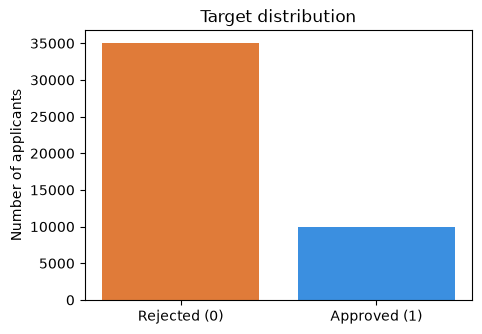

In [32]:
target_counts = data_frame["loan_status"].value_counts()
print(data_frame["loan_status"].value_counts(normalize=True).round(3))

fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Rejected (0)", "Approved (1)"], [target_counts.get(0, 0), target_counts.get(1, 0)],
       color=["#e07b39", "#3b8fe0"])
ax.set_ylabel("Number of applicants")
ax.set_title("Target distribution")
ax.grid(False)
plt.savefig("images/target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.2 Summary statistics
`describe()` helps us spot **outliers**. Look at the `max` of `person_age` and `person_emp_exp`: unrealistic values (for example an age above 100) are data errors and must be removed.

In [33]:
data_frame.describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,45000.0,27.764178,6.045108,20.00,24.00,26.00,30.00,144.00
person_income,45000.0,80319.053222,80422.498632,8000.00,47204.00,67048.00,95789.25,7200766.00
person_emp_exp,45000.0,5.410333,6.063532,0.00,1.00,4.00,8.00,125.00
loan_amnt,45000.0,9583.157556,6314.886691,500.00,5000.00,8000.00,12237.25,35000.00
loan_int_rate,45000.0,11.006606,2.978808,5.42,8.59,11.01,12.99,20.00
loan_percent_income,45000.0,0.139725,0.087212,0.00,0.07,0.12,0.19,0.66
cb_person_cred_hist_length,45000.0,5.867489,3.879702,2.00,3.00,4.00,8.00,30.00
credit_score,45000.0,632.608756,50.435865,390.00,601.00,640.00,670.00,850.00
loan_status,45000.0,0.222222,0.415744,0.00,0.00,0.00,0.00,1.00


### 3.3 Approval rate by category
For each categorical column we plot the share of approved loans. This gives an early idea of which features matter.

Categorical columns: ['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']


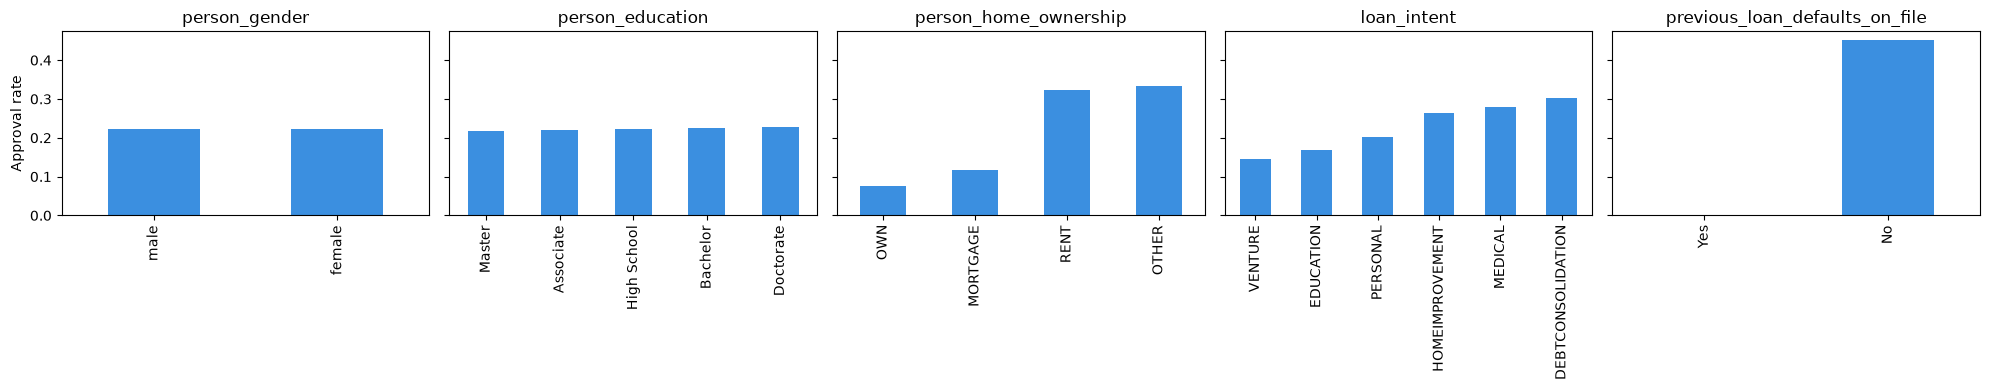

In [34]:
categorical_cols = data_frame.select_dtypes(include="object").columns.tolist()
print("Categorical columns:", categorical_cols)

fig, axes = plt.subplots(1, len(categorical_cols), figsize=(4 * len(categorical_cols), 4), sharey=True)
for ax, col in zip(np.atleast_1d(axes), categorical_cols):
    data_frame.groupby(col)["loan_status"].mean().sort_values().plot.bar(ax=ax, color="#3b8fe0")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.grid(False)
np.atleast_1d(axes)[0].set_ylabel("Approval rate")
plt.tight_layout()
plt.savefig("images/approval_rate_by_category.png", dpi=150, bbox_inches="tight")
plt.show()

### 3.4 Correlation of numeric features
Strongly correlated features carry similar information. For example, `loan_percent_income` is calculated from `loan_amnt` and `person_income`. A Decision Tree is not affected by this, but it matters for Logistic Regression.

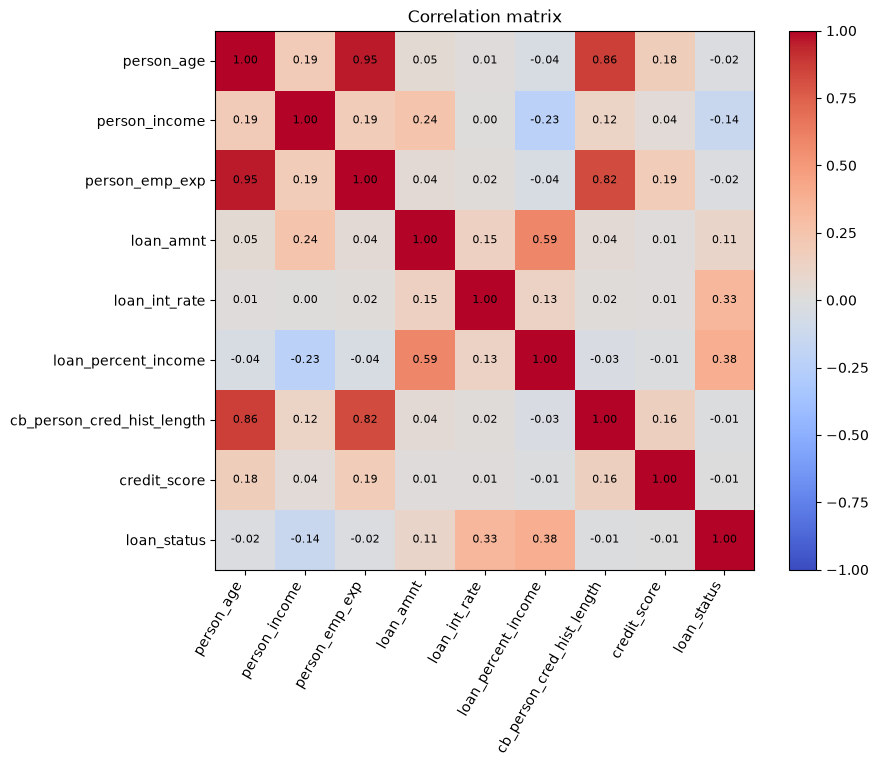

In [35]:
corr = data_frame.select_dtypes(include="number").corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=60, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(im)
ax.set_title("Correlation matrix")
plt.savefig("images/correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Data Cleaning
We remove two kinds of problems:
- **Duplicate rows**, which would appear in both the train and test sets and make the test score look better than it really is.
- **Impossible values**: ages above 80 and more than 60 years of work experience are treated as data errors.

In [36]:
rows_before = len(data_frame)

data_frame = data_frame.drop_duplicates()
data_frame = data_frame[(data_frame["person_age"] <= 80) & (data_frame["person_emp_exp"] <= 60)]
data_frame = data_frame.reset_index(drop=True)

print(f"Rows before: {rows_before}")
print(f"Rows after : {len(data_frame)}")
print(f"Removed    : {rows_before - len(data_frame)}")

Rows before: 45000
Rows after : 44990
Removed    : 10


## 5. Preprocessing and Train / Test Split
- **One-hot encoding** (`get_dummies`) converts text columns into 0/1 columns. `drop_first=True` removes one redundant column per feature.
- **Stratified split** keeps the same approve / reject ratio in both sets. This matters because the classes are imbalanced.
- The test set (20%) is **not touched** until the final comparison. All tuning is done on the training set only.

In [37]:
X = pd.get_dummies(data_frame.drop(columns="loan_status"), drop_first=True)
y = data_frame["loan_status"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Approval rate  train:", round(y_train.mean(), 3), "| test:", round(y_test.mean(), 3))

Train: (35992, 22) | Test: (8998, 22)
Approval rate  train: 0.222 | test: 0.222


## 6. Helper Function for Evaluation
To compare models fairly we use one function that reports the same metrics every time. The **Approve class (1)** is our main interest, so we track its precision, recall and F1:

| Metric | Question it answers | Business meaning |
|---|---|---|
| **Precision** | Of the loans we approved, how many should have been approved? | Low precision means risky loans get approved (bank loses money). |
| **Recall** | Of all loans that should be approved, how many did we approve? | Low recall means good customers are rejected (bank loses business). |
| **F1** | Balance of precision and recall | Single number to compare models. |
| **ROC AUC** | How well the model ranks approvals above rejections | Independent of the decision threshold. |

In [38]:
results = []   # every evaluated model is stored here for the final comparison

def evaluate(model, name, show_plot=True):
    """Evaluate a fitted model on the test set, print the report and store the metrics."""
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]

    metrics = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (Approve)": precision_score(y_test, pred),
        "Recall (Approve)": recall_score(y_test, pred),
        "F1 (Approve)": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, proba),
    }
    results.append(metrics)

    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["Reject", "Approve"]))

    if show_plot:
        fig, ax = plt.subplots(figsize=(4.5, 4))
        ConfusionMatrixDisplay.from_predictions(
            y_test, pred, display_labels=["Reject", "Approve"], cmap="Blues", ax=ax, colorbar=False)
        ax.set_title(f"Confusion matrix: {name}")
        ax.grid(False)
        plt.show()
    return metrics

## 7. Baseline Decision Tree
We start with a shallow tree (`max_depth=5`). A shallow tree is easy to read and less likely to overfit.

=== Decision Tree (depth=5) ===
              precision    recall  f1-score   support

      Reject       0.92      0.97      0.94      6998
     Approve       0.86      0.72      0.78      2000

    accuracy                           0.91      8998
   macro avg       0.89      0.84      0.86      8998
weighted avg       0.91      0.91      0.91      8998



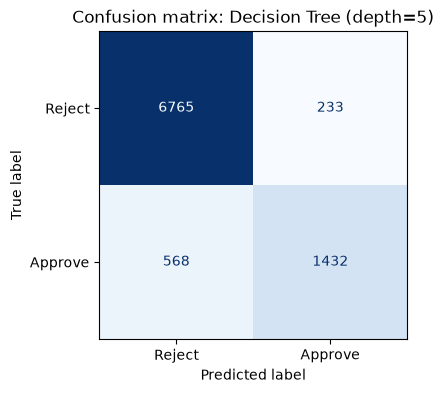

In [39]:
tree = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)

_ = evaluate(tree, "Decision Tree (depth=5)")

**How to read the confusion matrix:**
- Top-left: correctly rejected. Bottom-right: correctly approved.
- Top-right (**false approvals**): bad loans approved. This is usually the most expensive mistake for a bank.
- Bottom-left (**false rejections**): good customers turned away. This is lost business.

## 8. Feature Importance
Feature importance shows how much each feature reduced impurity across the tree. Higher means the feature was more useful for the decisions.

previous_loan_defaults_on_file_Yes    0.4721
loan_percent_income                   0.2070
loan_int_rate                         0.1905
person_income                         0.0712
person_home_ownership_RENT            0.0530
loan_intent_MEDICAL                   0.0062
person_emp_exp                        0.0000
loan_amnt                             0.0000
person_age                            0.0000
cb_person_cred_hist_length            0.0000
dtype: float64


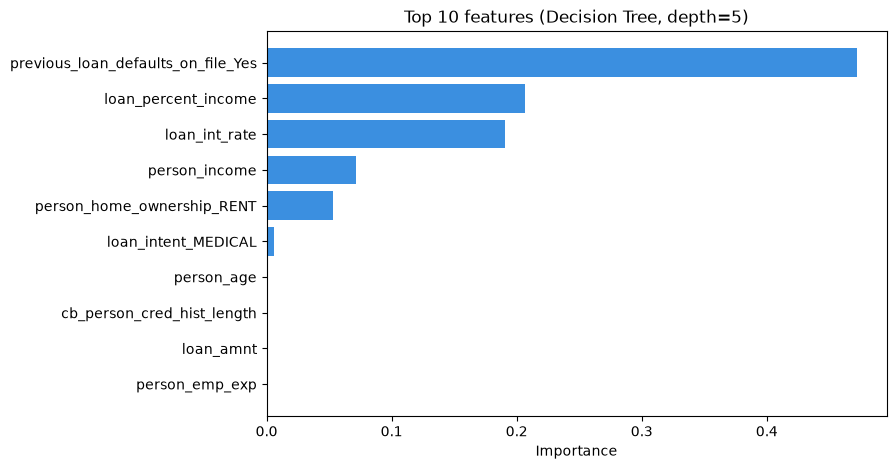

In [40]:
importances = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(10).round(4))

top = importances.head(10).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top.index, top.values, color="#3b8fe0")
ax.set_xlabel("Importance")
ax.set_title("Top 10 features (Decision Tree, depth=5)")
ax.grid(False)
plt.savefig("images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Visualize the Tree
Only the first 3 levels are drawn to keep the figure readable. Each box shows the split rule, the Gini value, the number of samples, the class counts `[Reject, Approve]` and the majority class.

**Things to look for:**
- The **root split** is the single most informative question in the data.
- A box with `gini = 0.0` is a *pure* node: every sample in it belongs to one class.

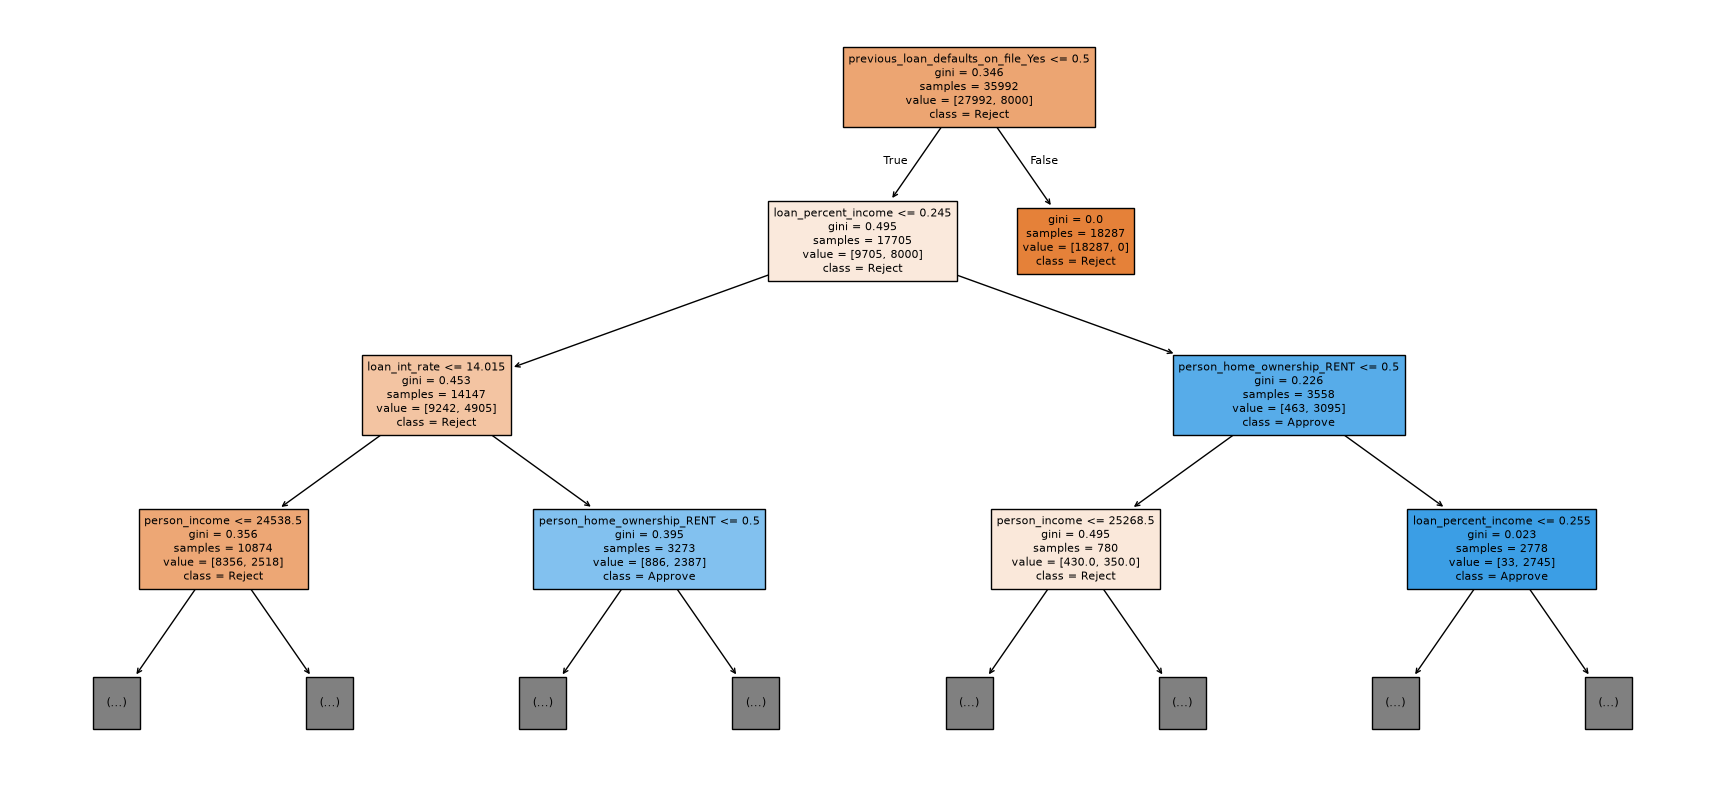

In [41]:
plt.figure(figsize=(22, 10))
plot_tree(
    tree,
    feature_names=X.columns,
    class_names=["Reject", "Approve"],
    filled=True,
    max_depth=3,
    fontsize=8,
)
plt.savefig("images/decision_tree.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Overfitting Study: `max_depth`
**Overfitting** happens when a model memorizes the training data (including noise) and performs worse on new data. A deeper tree has more rules and can memorize more.

We use **5-fold cross-validation on the training set** (not the test set) to measure the validation score for each depth. This keeps the test set clean for the final evaluation.
- Training score keeps rising with depth.
- Validation score rises first, then flattens or drops. The gap between the two lines is the overfitting.

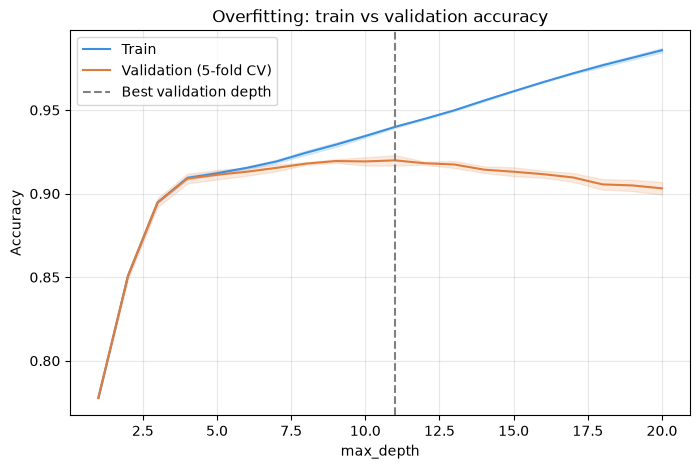

Best depth by validation accuracy: 11
Train accuracy at depth 20     : 0.9858
Validation accuracy at depth 20: 0.9031


In [42]:
depths = np.arange(1, 21)

train_scores, val_scores = validation_curve(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    X_train, y_train,
    param_name="max_depth",
    param_range=depths,
    cv=5,
    scoring="accuracy",
    n_jobs=-1,
)

train_mean, train_std = train_scores.mean(axis=1), train_scores.std(axis=1)
val_mean, val_std = val_scores.mean(axis=1), val_scores.std(axis=1)

plt.figure(figsize=(8, 5))
plt.plot(depths, train_mean, label="Train", color="#3b8fe0")
plt.fill_between(depths, train_mean - train_std, train_mean + train_std, alpha=0.15, color="#3b8fe0")
plt.plot(depths, val_mean, label="Validation (5-fold CV)", color="#e07b39")
plt.fill_between(depths, val_mean - val_std, val_mean + val_std, alpha=0.15, color="#e07b39")
plt.axvline(depths[val_mean.argmax()], color="gray", linestyle="--", label="Best validation depth")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Overfitting: train vs validation accuracy")
plt.legend()
plt.savefig("images/overfitting.png", dpi=150, bbox_inches="tight")
plt.show()

print("Best depth by validation accuracy:", depths[val_mean.argmax()])
print("Train accuracy at depth 20     :", round(train_mean[-1], 4))
print("Validation accuracy at depth 20:", round(val_mean[-1], 4))

## 11. Logistic Regression for Comparison
Logistic Regression is a linear model. Unlike a tree, it is sensitive to the scale of features, so we use `StandardScaler` inside a pipeline. The scaler is fitted only on the training data, which avoids data leakage.

=== Logistic Regression ===
              precision    recall  f1-score   support

      Reject       0.93      0.94      0.93      6998
     Approve       0.78      0.75      0.76      2000

    accuracy                           0.90      8998
   macro avg       0.85      0.84      0.85      8998
weighted avg       0.90      0.90      0.90      8998



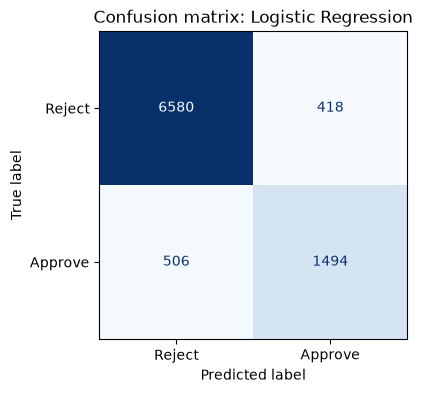

In [43]:
lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
lr.fit(X_train, y_train)

_ = evaluate(lr, "Logistic Regression")

## 12. Handling Class Imbalance
Approved loans are the minority class, so the tree tends to favour "Reject". With `class_weight="balanced"` the model pays more attention to the minority class. Expect **higher recall** for Approve, usually at the cost of **lower precision**. Whether that trade-off is acceptable is a business decision.

=== Decision Tree (depth=8, balanced) ===
              precision    recall  f1-score   support

      Reject       0.97      0.88      0.92      6998
     Approve       0.68      0.90      0.77      2000

    accuracy                           0.88      8998
   macro avg       0.82      0.89      0.85      8998
weighted avg       0.90      0.88      0.89      8998



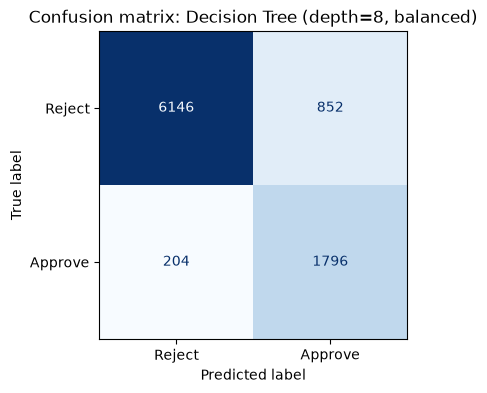

In [44]:
tree_balanced = DecisionTreeClassifier(max_depth=8, class_weight="balanced", random_state=RANDOM_STATE)
tree_balanced.fit(X_train, y_train)

_ = evaluate(tree_balanced, "Decision Tree (depth=8, balanced)")

## 13. Hyperparameter Tuning with GridSearchCV
Instead of guessing parameters, `GridSearchCV` tries every combination using 5-fold cross-validation on the training data and keeps the best one.

- `max_depth`: maximum number of levels
- `min_samples_leaf`: minimum number of samples a leaf must have. Larger values stop the tree from creating tiny, noisy leaves (a strong protection against overfitting).
- `class_weight`: with and without balancing
- `scoring="f1"`: optimizes the F1 score of the Approve class instead of accuracy, which is better for imbalanced data

> If the best value lands on the **edge** of a grid (the smallest or largest value you tried), extend the grid in that direction and run again.

In [45]:
param_grid = {
    "max_depth": [6, 8, 10, 12, 14, 16, 20, None],
    "min_samples_leaf": [10, 20, 50, 100, 200],
    "class_weight": [None, "balanced"],
}

grid = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Best parameters :", grid.best_params_)
print("Best CV F1 score:", round(grid.best_score_, 4))

cv_results = (
    pd.DataFrame(grid.cv_results_)
    .sort_values("rank_test_score")
    [["param_max_depth", "param_min_samples_leaf", "param_class_weight", "mean_test_score", "std_test_score"]]
    .head(5)
)
cv_results

Best parameters : {'class_weight': None, 'max_depth': 16, 'min_samples_leaf': 50}
Best CV F1 score: 0.8043


,param_max_depth,param_min_samples_leaf,param_class_weight,mean_test_score,std_test_score
27,16,50,None,0.804338,0.005015
32,20,50,None,0.804008,0.005175
37,None,50,None,0.804008,0.005175
22,14,50,None,0.803587,0.004343
26,16,20,None,0.803210,0.003587


### Evaluate the tuned model
This is the first time the tuned model sees the test set.

=== Decision Tree (tuned) ===
              precision    recall  f1-score   support

      Reject       0.94      0.97      0.95      6998
     Approve       0.87      0.77      0.81      2000

    accuracy                           0.92      8998
   macro avg       0.90      0.87      0.88      8998
weighted avg       0.92      0.92      0.92      8998



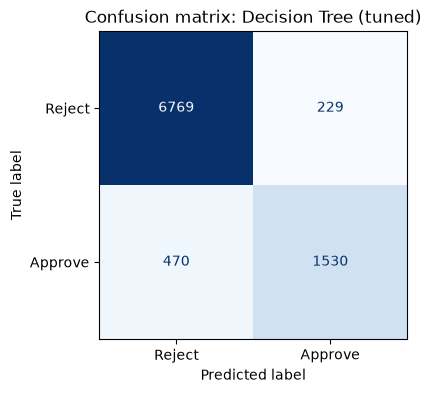

In [46]:
best_tree = grid.best_estimator_
_ = evaluate(best_tree, "Decision Tree (tuned)")

## 14. Final Model Comparison
All models are evaluated on the **same untouched test set**.

In [47]:
comparison = pd.DataFrame(results).set_index("Model").round(4)
comparison.sort_values("F1 (Approve)", ascending=False)

,Accuracy,Precision (Approve),Recall (Approve),F1 (Approve),ROC AUC
Model,,,,,
Decision Tree (tuned),0.9223,0.8698,0.765,0.8140,0.9641
Decision Tree (depth=5),0.9110,0.8601,0.716,0.7814,0.9532
"Decision Tree (depth=8, balanced)",0.8826,0.6782,0.898,0.7728,0.9641
Logistic Regression,0.8973,0.7814,0.747,0.7638,0.9540


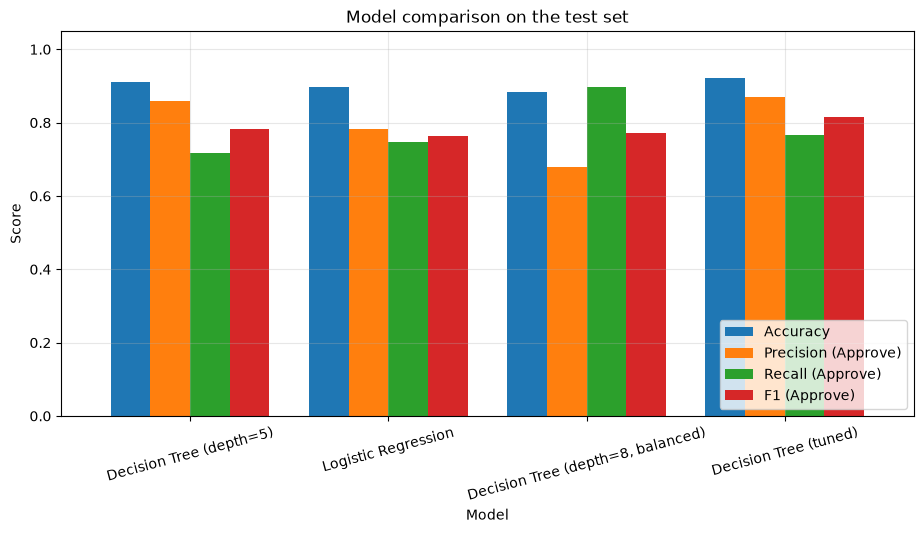

In [48]:
metric_cols = ["Accuracy", "Precision (Approve)", "Recall (Approve)", "F1 (Approve)"]
comparison[metric_cols].plot.bar(figsize=(11, 5), rot=15, width=0.8)
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.title("Model comparison on the test set")
plt.legend(loc="lower right")
plt.savefig("images/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

### ROC Curves
The ROC curve shows the trade-off between catching true approvals and wrongly approving bad loans at every threshold. The closer the curve is to the top-left corner (higher AUC), the better.

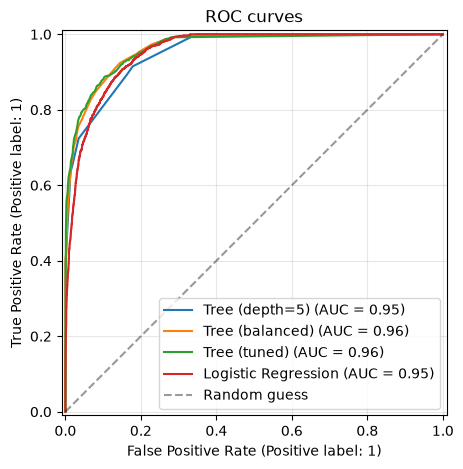

In [49]:
fig, ax = plt.subplots(figsize=(6, 5))
for model, name in [
    (tree, "Tree (depth=5)"),
    (tree_balanced, "Tree (balanced)"),
    (best_tree, "Tree (tuned)"),
    (lr, "Logistic Regression"),
]:
    RocCurveDisplay.from_estimator(model, X_test, y_test, name=name, ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4, label="Random guess")
ax.legend(loc="lower right")
ax.set_title("ROC curves")
plt.savefig("images/roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 15. Tuned Model: Feature Importance and Saving
We check which features the final model relies on, then save it so it can be reused without retraining.

In [50]:
imp_best = pd.Series(best_tree.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp_best.head(10).round(4))

previous_loan_defaults_on_file_Yes    0.4166
loan_percent_income                   0.1860
loan_int_rate                         0.1819
person_income                         0.0996
person_home_ownership_RENT            0.0500
credit_score                          0.0181
loan_intent_HOMEIMPROVEMENT           0.0097
loan_intent_VENTURE                   0.0085
loan_intent_MEDICAL                   0.0076
person_home_ownership_OWN             0.0070
dtype: float64


In [51]:
import joblib

joblib.dump(best_tree, "models/loan_decision_tree.joblib")
joblib.dump(list(X.columns), "models/feature_columns.joblib")
print("Model saved to models/")

Model saved to models/


### Example: predict for a new applicant
New data must go through the **same one-hot encoding** and have the **same columns** as the training data. `reindex` adds missing dummy columns with 0.

In [52]:
sample = data_frame.drop(columns="loan_status").iloc[[0]]   # replace with your own applicant data
sample_encoded = pd.get_dummies(sample).reindex(columns=X.columns, fill_value=0)

prediction = best_tree.predict(sample_encoded)[0]
probability = best_tree.predict_proba(sample_encoded)[0, 1]
print("Decision:", "Approved" if prediction == 1 else "Rejected")
print(f"Approval probability: {probability:.2%}")

Decision: Approved
Approval probability: 100.00%


## 16. Conclusions and Key Takeaways

1. **Previous defaults decide almost everything.** The root split of the tree is `previous_loan_defaults_on_file`. Applicants with a previous default are rejected by the tree with no exceptions (a pure node).
2. **Loan size relative to income matters next.** After the default check, `loan_percent_income`, `loan_int_rate`, `person_home_ownership` and `person_income` drive the decisions.
3. **Depth controls overfitting.** Training accuracy keeps rising as the tree gets deeper while validation accuracy flattens and then drops. Limiting `max_depth` and using `min_samples_leaf` gives a simpler tree that generalizes better.
4. **Accuracy is not enough.** The data is imbalanced (about 78% rejected, 22% approved), so precision, recall and F1 of the Approve class are reported. Balancing the classes improves recall but lowers precision, and the right choice depends on whether the bank fears bad loans or lost customers more.
5. **Tuning with cross-validation** (and keeping the test set untouched until the end) gives an honest estimate of real-world performance.
6. **Limitations:** the dataset is synthetic, so some patterns (for example, how `loan_percent_income` relates to approval) may not match real banks. A single tree is also unstable: small changes in data can change its structure.

### Next step
A **Random Forest** combines many trees and usually fixes the instability and overfitting of a single tree. We will run it on this same dataset for a direct comparison.